<a href="https://colab.research.google.com/github/ReyAndrey22/Machine-Learning-Laboratories/blob/main/Laborator_4_%C3%8Env%C4%83%C8%9Bare_automat%C4%83.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.metrics import davies_bouldin_score

In [ ]:
df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/Laboratoare_Învățare_automată/Lab4/CC GENERAL.csv')
df.head(10)

,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.40,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.00,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.00,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.00,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.00,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12
5,C10006,1809.828751,1.000000,1333.28,0.00,1333.28,0.000000,0.666667,0.000000,0.583333,0.000000,0,8,1800.0,1400.057770,2407.246035,0.000000,12
6,C10007,627.260806,1.000000,7091.01,6402.63,688.38,0.000000,1.000000,1.000000,1.000000,0.000000,0,64,13500.0,6354.314328,198.065894,1.000000,12
7,C10008,1823.652743,1.000000,436.20,0.00,436.20,0.000000,1.000000,0.000000,1.000000,0.000000,0,12,2300.0,679.065082,532.033990,0.000000,12
8,C10009,1014.926473,1.000000,861.49,661.49,200.00,0.000000,0.333333,0.083333,0.250000,0.000000,0,5,7000.0,688.278568,311.963409,0.000000,12
9,C10010,152.225975,0.545455,1281.60,1281.60,0.00,0.000000,0.166667,0.166667,0.000000,0.000000,0,3,11000.0,1164.770591,100.302262,0.000000,12


In [ ]:
print("Shape of the dataset: " + str(df.shape))
df.info()
print(df.duplicated().sum())
print(df.isnull().sum())

Shape of the dataset: (8950, 18)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8950 entries, 0 to 8949
Data columns (total 18 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   CUST_ID                           8950 non-null   object 
 1   BALANCE                           8950 non-null   float64
 2   BALANCE_FREQUENCY                 8950 non-null   float64
 3   PURCHASES                         8950 non-null   float64
 4   ONEOFF_PURCHASES                  8950 non-null   float64
 5   INSTALLMENTS_PURCHASES            8950 non-null   float64
 6   CASH_ADVANCE                      8950 non-null   float64
 7   PURCHASES_FREQUENCY               8950 non-null   float64
 8   ONEOFF_PURCHASES_FREQUENCY        8950 non-null   float64
 9   PURCHASES_INSTALLMENTS_FREQUENCY  8950 non-null   float64
 10  CASH_ADVANCE_FREQUENCY            8950 non-null   float64
 11  CASH_ADVANCE_TRX                  89

In [ ]:
df = df.dropna()
df.drop('CUST_ID', axis=1, inplace=True)
print("Shape of the dataset after data cleaning: " + str(df.shape))
df.head(10)

Shape of the dataset after data cleaning: (8636, 17)


,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,40.900749,0.818182,95.40,0.00,95.40,0.000000,0.166667,0.000000,0.083333,0.00,0,2,1000.0,201.802084,139.509787,0.000000,12
1,3202.467416,0.909091,0.00,0.00,0.00,6442.945483,0.000000,0.000000,0.000000,0.25,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,2495.148862,1.000000,773.17,773.17,0.00,0.000000,1.000000,1.000000,0.000000,0.00,0,12,7500.0,622.066742,627.284787,0.000000,12
4,817.714335,1.000000,16.00,16.00,0.00,0.000000,0.083333,0.083333,0.000000,0.00,0,1,1200.0,678.334763,244.791237,0.000000,12
5,1809.828751,1.000000,1333.28,0.00,1333.28,0.000000,0.666667,0.000000,0.583333,0.00,0,8,1800.0,1400.057770,2407.246035,0.000000,12
6,627.260806,1.000000,7091.01,6402.63,688.38,0.000000,1.000000,1.000000,1.000000,0.00,0,64,13500.0,6354.314328,198.065894,1.000000,12
7,1823.652743,1.000000,436.20,0.00,436.20,0.000000,1.000000,0.000000,1.000000,0.00,0,12,2300.0,679.065082,532.033990,0.000000,12
8,1014.926473,1.000000,861.49,661.49,200.00,0.000000,0.333333,0.083333,0.250000,0.00,0,5,7000.0,688.278568,311.963409,0.000000,12
9,152.225975,0.545455,1281.60,1281.60,0.00,0.000000,0.166667,0.166667,0.000000,0.00,0,3,11000.0,1164.770591,100.302262,0.000000,12
10,1293.124939,1.000000,920.12,0.00,920.12,0.000000,1.000000,0.000000,1.000000,0.00,0,12,1200.0,1083.301007,2172.697765,0.000000,12


In [ ]:
df.describe()

,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
count,8636.000000,8636.000000,8636.000000,8636.000000,8636.000000,8636.000000,8636.000000,8636.000000,8636.000000,8636.000000,8636.000000,8636.000000,8636.000000,8636.000000,8636.000000,8636.000000,8636.000000
mean,1601.224893,0.895035,1025.433874,604.901438,420.843533,994.175523,0.496000,0.205909,0.368820,0.137604,3.313918,15.033233,4522.091030,1784.478099,864.304943,0.159304,11.534391
std,2095.571300,0.207697,2167.107984,1684.307803,917.245182,2121.458303,0.401273,0.300054,0.398093,0.201791,6.912506,25.180468,3659.240379,2909.810090,2372.566350,0.296271,1.310984
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,50.000000,0.049513,0.019163,0.000000,6.000000
25%,148.095189,0.909091,43.367500,0.000000,0.000000,0.000000,0.083333,0.000000,0.000000,0.000000,0.000000,1.000000,1600.000000,418.559237,169.163545,0.000000,12.000000
50%,916.855459,1.000000,375.405000,44.995000,94.785000,0.000000,0.500000,0.083333,0.166667,0.000000,0.000000,7.000000,3000.000000,896.675701,312.452292,0.000000,12.000000
75%,2105.195853,1.000000,1145.980000,599.100000,484.147500,1132.385490,0.916667,0.333333,0.750000,0.250000,4.000000,18.000000,6500.000000,1951.142090,825.496463,0.166667,12.000000
max,19043.138560,1.000000,49039.570000,40761.250000,22500.000000,47137.211760,1.000000,1.000000,1.000000,1.500000,123.000000,358.000000,30000.000000,50721.483360,76406.207520,1.000000,12.000000


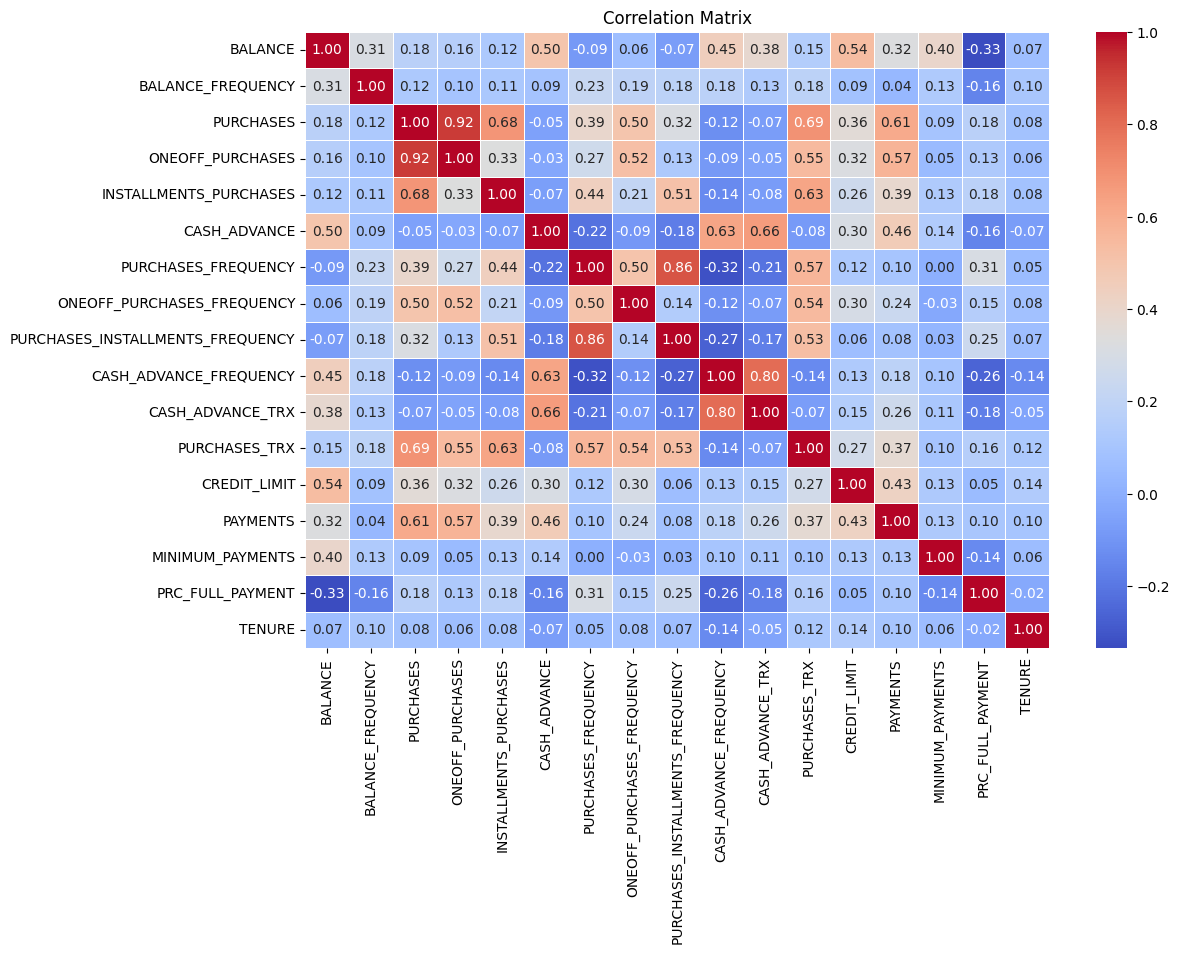

In [ ]:
plt.figure(figsize=(12,8))
sns.heatmap(df.corr(), cmap="coolwarm", annot=True, fmt=".2f", linewidths=0.5)
plt.title("Correlation Matrix")
plt.show()


In [ ]:
features = ['BALANCE','PURCHASES','CASH_ADVANCE','CREDIT_LIMIT','PAYMENTS','TENURE']
df_selected_features = df[features]
scaler = StandardScaler()
df_scaled = scaler.fit_transform(df_selected_features)


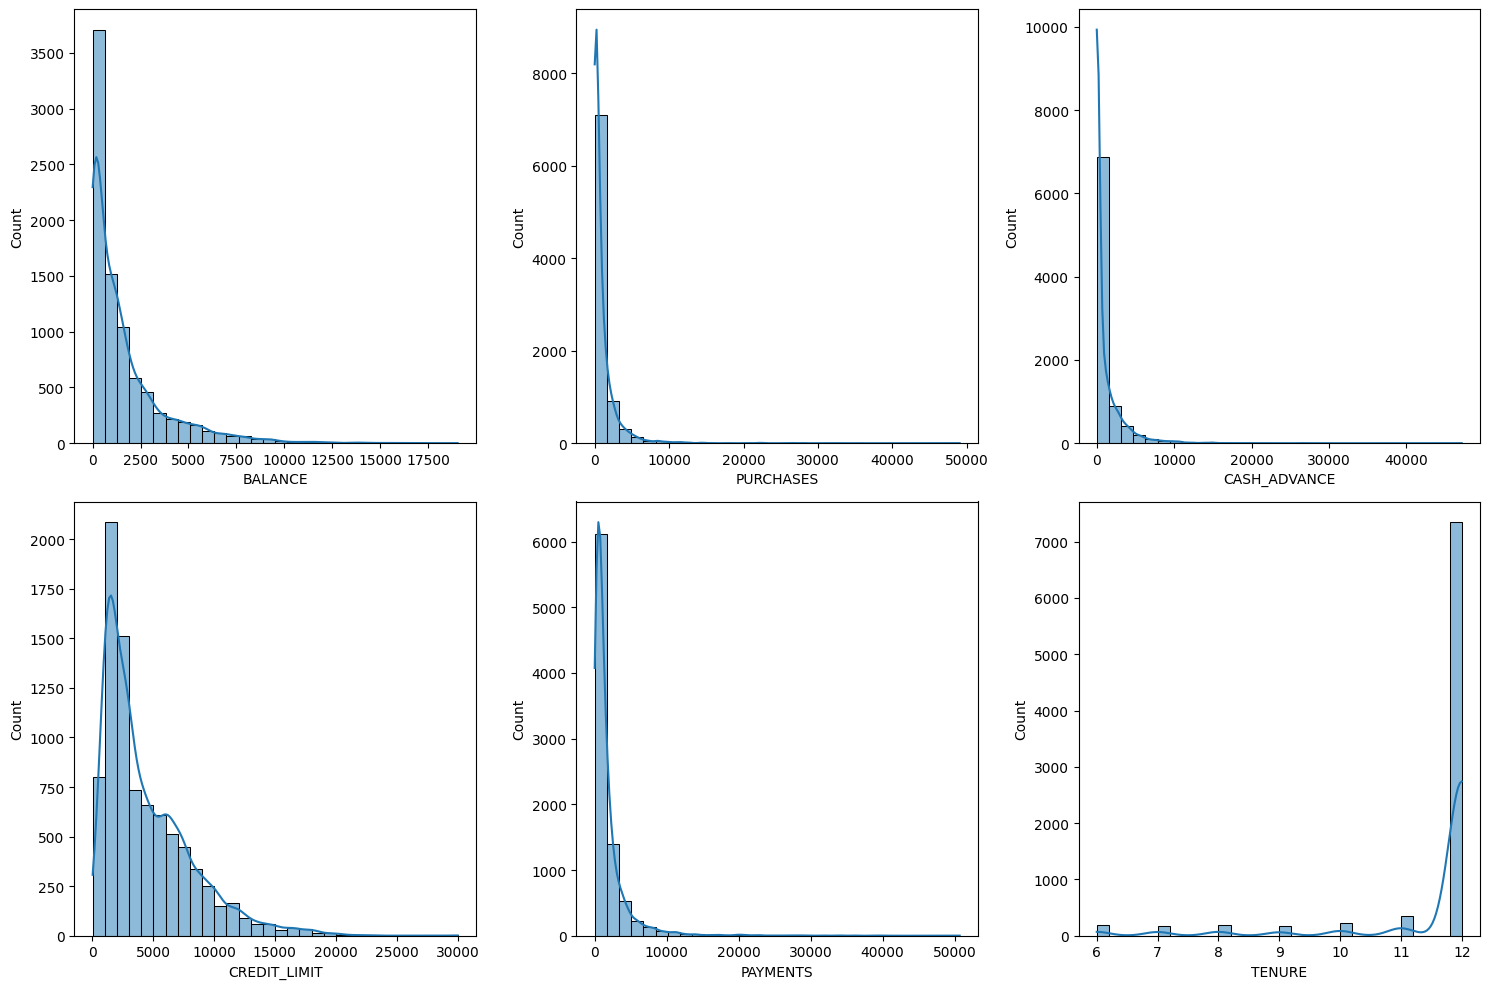

In [ ]:
plt.figure(figsize=(15,10))

for i, feature in enumerate(features):
    plt.subplot(2, 3, i+1)
    sns.histplot(df_selected_features[feature], bins=30, kde=True)
    plt.xlabel(feature)
    plt.ylabel('Count')

plt.tight_layout()
plt.show()

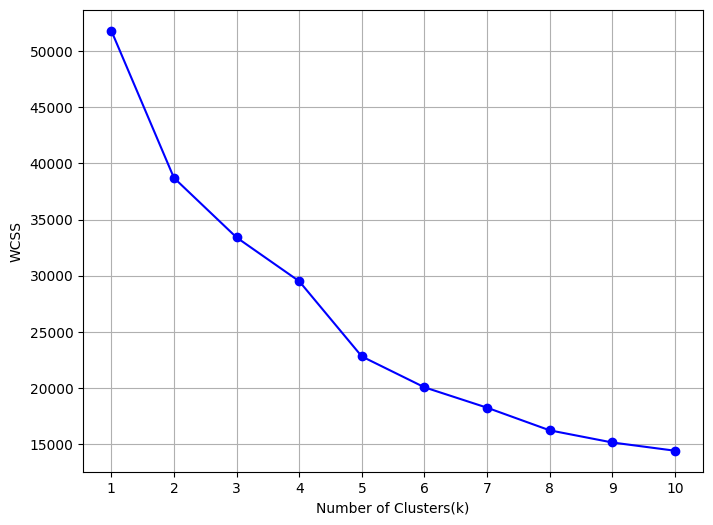

In [ ]:
wcss = []
max_clusters = 10
for i in range(1, max_clusters + 1):
    kmeans = KMeans(n_clusters=i, random_state=42)
    kmeans.fit(df_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 6))
plt.plot(range(1, max_clusters + 1), wcss, marker='o', linestyle='-', color='b')
plt.xlabel("Number of Clusters(k)")
plt.ylabel("WCSS")
plt.xticks(range(1, max_clusters + 1))
plt.grid(True)
plt.show()

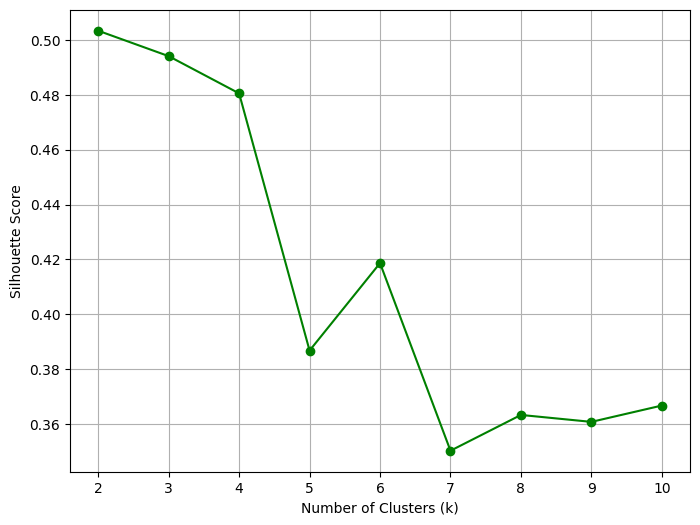

In [ ]:
scores = []
max_clusters = 10

for k in range(2, max_clusters + 1):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(df_scaled)
    score = silhouette_score(df_scaled, labels)
    scores.append(score)

plt.figure(figsize=(8, 6))
plt.plot(range(2, max_clusters + 1), scores, marker='o', linestyle='-', color='green')
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.xticks(range(2, max_clusters + 1))
plt.grid(True)
plt.show()

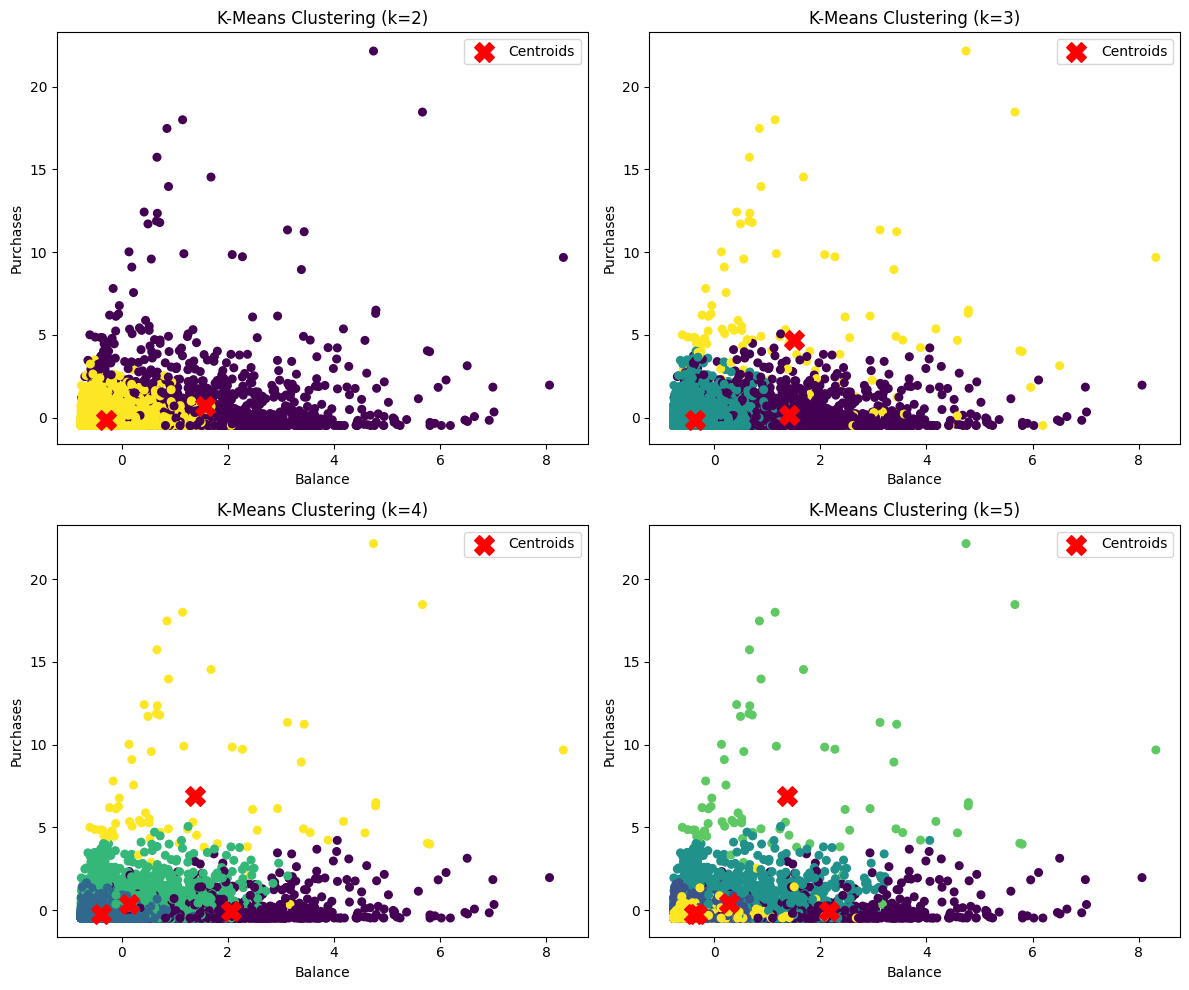

In [ ]:
k_values = [2, 3, 4, 5]

plt.figure(figsize=(12, 10))

for i, k in enumerate(k_values, 1):
    kmeans = KMeans(n_clusters=k, random_state=42)
    y_kmeans = kmeans.fit_predict(df_scaled)

    plt.subplot(2, 2, i)
    plt.scatter(df_scaled[:, 0], df_scaled[:, 1], c=y_kmeans, cmap='viridis', s=30)
    plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1],
                s=200, c='red', marker='X', label='Centroids')
    plt.title(f"K-Means Clustering (k={k})")
    plt.xlabel("Balance")
    plt.ylabel("Purchases")
    plt.legend()

plt.tight_layout()
plt.show()

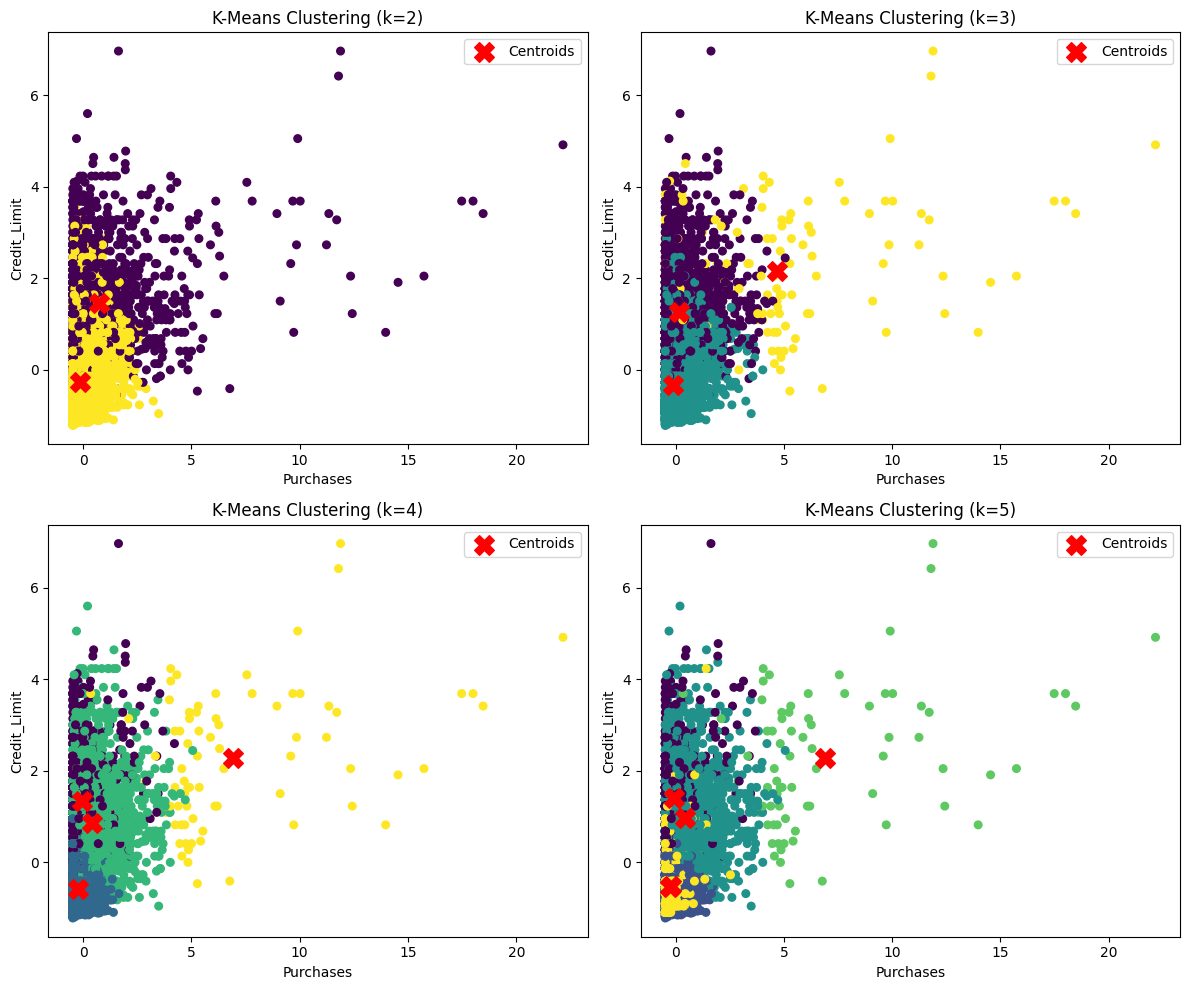

In [ ]:
k_values = [2, 3, 4, 5]

plt.figure(figsize=(12, 10))

for i, k in enumerate(k_values, 1):
    kmeans = KMeans(n_clusters=k, random_state=42)
    y_kmeans = kmeans.fit_predict(df_scaled)

    plt.subplot(2, 2, i)
    plt.scatter(df_scaled[:, 1], df_scaled[:, 3], c=y_kmeans, cmap='viridis', s=30)
    plt.scatter(kmeans.cluster_centers_[:, 1], kmeans.cluster_centers_[:, 3],
                s=200, c='red', marker='X', label='Centroids')
    plt.title(f"K-Means Clustering (k={k})")
    plt.xlabel("Purchases")
    plt.ylabel("Credit_Limit")
    plt.legend()

plt.tight_layout()
plt.show()

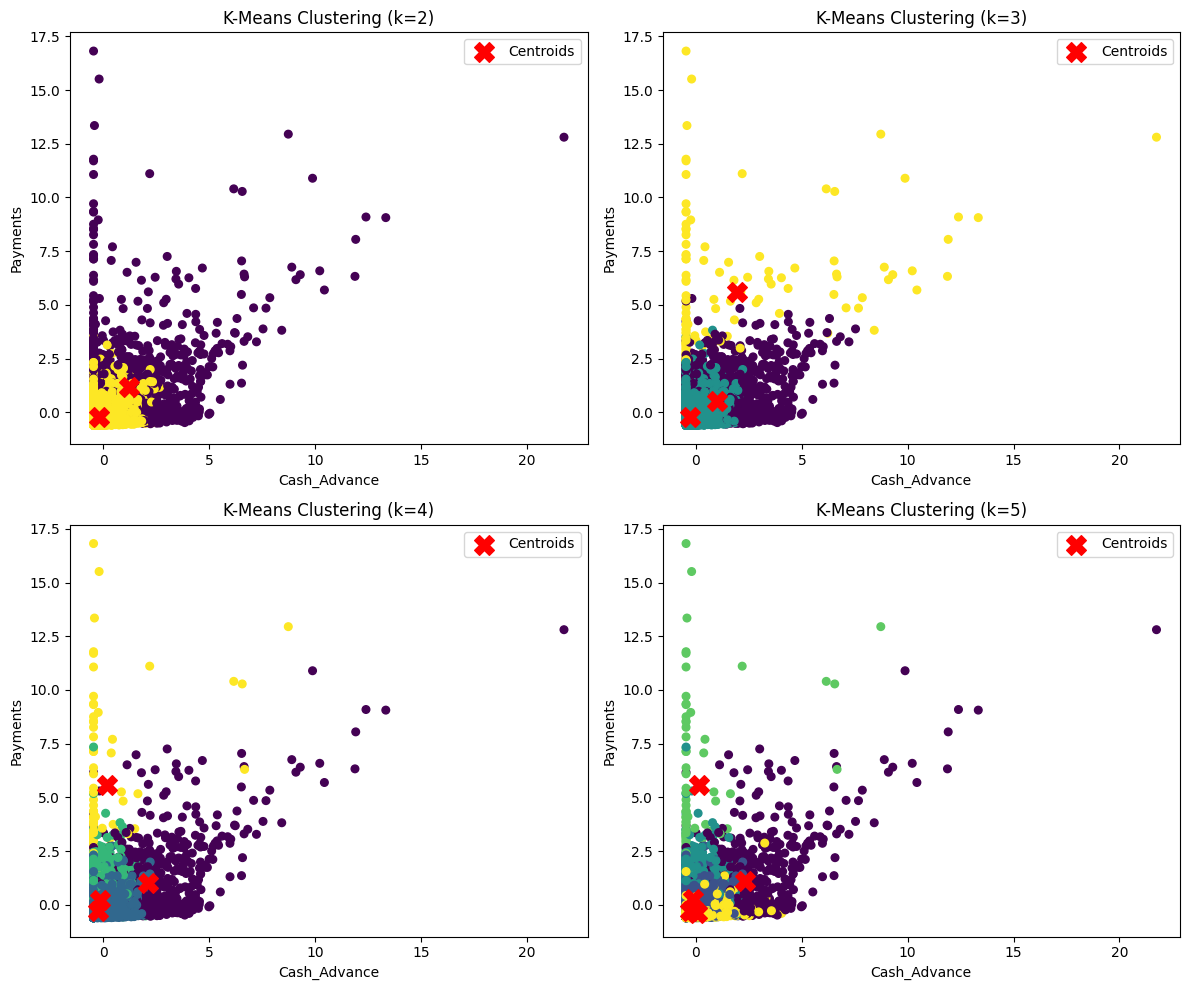

In [ ]:
k_values = [2, 3, 4, 5]

plt.figure(figsize=(12, 10))

for i, k in enumerate(k_values, 1):
    kmeans = KMeans(n_clusters=k, random_state=42)
    y_kmeans = kmeans.fit_predict(df_scaled)

    plt.subplot(2, 2, i)
    plt.scatter(df_scaled[:, 2], df_scaled[:, 4], c=y_kmeans, cmap='viridis', s=30)
    plt.scatter(kmeans.cluster_centers_[:, 2], kmeans.cluster_centers_[:, 4],
                s=200, c='red', marker='X', label='Centroids')
    plt.title(f"K-Means Clustering (k={k})")
    plt.xlabel("Cash_Advance")
    plt.ylabel("Payments")
    plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
optimal_k = 3
kmeans = KMeans(n_clusters=optimal_k, random_state=42)
kmeans_clusters = kmeans.fit_predict(df_scaled)
df['Cluster'] = kmeans_clusters
print(df[['BALANCE','PURCHASES','CASH_ADVANCE','CREDIT_LIMIT','PAYMENTS','TENURE','Cluster']].head(10))
print(df['Cluster'].value_counts().sort_index())

        BALANCE  PURCHASES  CASH_ADVANCE  CREDIT_LIMIT     PAYMENTS  TENURE  \
0     40.900749      95.40      0.000000        1000.0   201.802084      12   
1   3202.467416       0.00   6442.945483        7000.0  4103.032597      12   
2   2495.148862     773.17      0.000000        7500.0   622.066742      12   
4    817.714335      16.00      0.000000        1200.0   678.334763      12   
5   1809.828751    1333.28      0.000000        1800.0  1400.057770      12   
6    627.260806    7091.01      0.000000       13500.0  6354.314328      12   
7   1823.652743     436.20      0.000000        2300.0   679.065082      12   
8   1014.926473     861.49      0.000000        7000.0   688.278568      12   
9    152.225975    1281.60      0.000000       11000.0  1164.770591      12   
10  1293.124939     920.12      0.000000        1200.0  1083.301007      12   

    Cluster  
0         1  
1         0  
2         1  
4         1  
5         1  
6         0  
7         1  
8         1  
9   

In [ ]:
kmeans_silhouette = silhouette_score(df_scaled, kmeans_clusters)
kmeans_davies_bouldin = davies_bouldin_score(df_scaled, kmeans_clusters)

print(f"Silhouette Score:        {kmeans_silhouette:.4f}")
print(f"Davies-Bouldin Index:    {kmeans_davies_bouldin:.4f}")

Silhouette Score:        0.4410
Davies-Bouldin Index:    1.2911


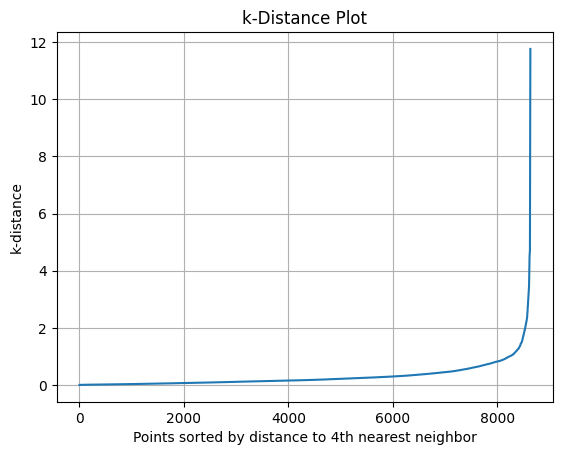

In [ ]:
k = 4
nearest_neighbors = NearestNeighbors(n_neighbors=k)
nearest_neighbors.fit(df_scaled)
distances, indices = nearest_neighbors.kneighbors(df_scaled)

distances = np.sort(distances[:, k - 1], axis=0)
plt.plot(distances)
plt.title("k-Distance Plot")
plt.xlabel("Points sorted by distance to {}th nearest neighbor".format(k))
plt.ylabel("k-distance")
plt.grid(True)
plt.show()

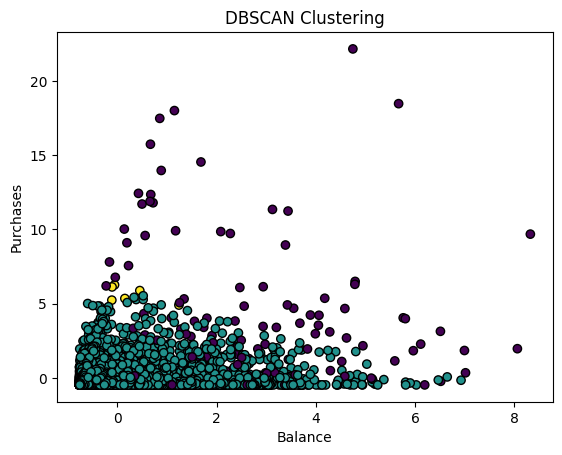

In [ ]:
dbscan = DBSCAN(eps=1.25, min_samples=5)
dbscan.fit(df_scaled)

labels = dbscan.labels_

plt.scatter(df_scaled[:, 0], df_scaled[:, 1], c=labels, cmap='viridis', marker='o', edgecolor='k')
plt.title("DBSCAN Clustering")
plt.xlabel("Balance")
plt.ylabel("Purchases")
plt.show()

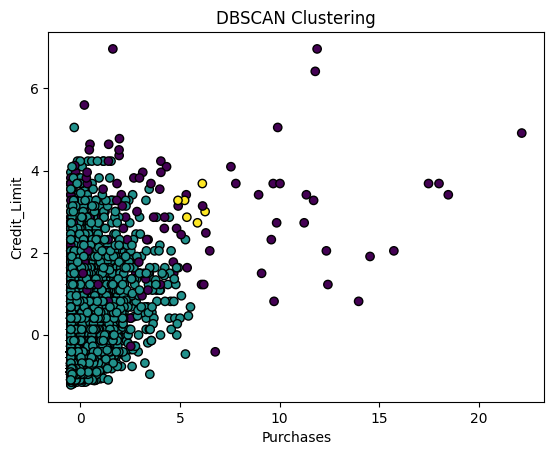

In [ ]:
dbscan = DBSCAN(eps=1.25, min_samples=5)
dbscan.fit(df_scaled)

labels = dbscan.labels_

plt.scatter(df_scaled[:, 1], df_scaled[:, 3], c=labels, cmap='viridis', marker='o', edgecolor='k')
plt.title("DBSCAN Clustering")
plt.xlabel("Purchases")
plt.ylabel("Credit_Limit")
plt.show()

In [ ]:
n_clusters_dbscan = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = list(labels).count(-1)

print(f"Estimated number of clusters: {n_clusters_dbscan}")
print(f"Estimated number of noise points: {n_noise}")

Estimated number of clusters: 2
Estimated number of noise points: 191


In [ ]:
if n_clusters_dbscan > 1:
    mask = labels != -1
    if sum(mask) > 0:
        dbscan_silhouette = silhouette_score(df_scaled[mask], labels[mask])
        dbscan_davies_bouldin = davies_bouldin_score(df_scaled[mask], labels[mask])

        print(f"Silhouette Score:        {dbscan_silhouette:.4f}")
        print(f"Davies-Bouldin Index:    {dbscan_davies_bouldin:.4f}")

Silhouette Score:        0.6945
Davies-Bouldin Index:    0.3177
